# Домашнее задание 1 по курсу RecSyS: базовые модели рекомендаций на MTS KION

Для первого задания я выбрал датасет онлайн-кинотеатра KION с историей просмотров пользователей. На его основе я буду рекомендовать каждому пользователю **10 фильмов, которые он ещё не смотрел**, и сравнивать качество разных рекомендательных моделей.

**В работе реализую с нуля пять моделей:**

1. **ItemKNN** - рекомендации на основе похожих фильмов.
2. **iALS** - матричная факторизация для неявной обратной связи.
3. **EASE** - линейная модель на основе связей между фильмами.
4. **FM** - факторизационная машина с признаками пользователей и фильмов.
5. **iALS с собственным таргетом** -  модификация, учитывающая процент досмотра фильма.

Также использую рекомендации по популярности как baseline для сравнения.

Код моделей находится в папке `models/`, весь анализ и сравнение результатов - в этом ноутбуке.

Для запуска достаточно установить библиотеки из `requirements.txt`. Датасет автоматически загрузится в папку `data/`.

In [ ]:
import zipfile
from itertools import product
from pathlib import Path
from time import perf_counter
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display, Markdown
from scipy.sparse import csr_matrix

from models import EASE, IALS, FactorizationMachine, IALSWatchTarget, ItemKNN, build_features, watch_target

SEED = 42
K = 10  
np.random.seed(SEED)
torch.manual_seed(SEED)
pd.options.display.max_columns = 20
pd.options.display.width = 200
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

## 1. Данные

Я взял открытый датасет онлайн-кинотеатра МТС KION ([репозиторий](https://github.com/irsafilo/KION_DATASET),
[статья](https://arxiv.org/abs/2209.00325), [описание полей](https://ods.ai/competitions/competition-recsys-21/data)).
Это реальные логи просмотров с марта по август 2021 года.

В архиве три таблицы:

| Файл | Что внутри |
|---|---|
| `interactions.csv` | пары пользователь–тайтл: дата последнего просмотра, суммарное время просмотра в секундах, процент досмотра |
| `users.csv` | возраст, доход, пол и наличие детей (категориями) |
| `items.csv` | тип (фильм или сериал), название, год, жанры, страны, режиссёры, актёры, возрастной рейтинг и т. д. |


In [ ]:
URL = "https://raw.githubusercontent.com/irsafilo/KION_DATASET/f69775be31fa5779907cf0a92ddedb70037fb5ae/data_original.zip"
archive = Path("data") / "data_original.zip"
archive.parent.mkdir(exist_ok=True)
if not archive.exists():
    urlretrieve(URL, archive)

with zipfile.ZipFile(archive) as z:
    interactions = pd.read_csv(z.open("data_original/interactions.csv"), parse_dates=["last_watch_dt"])
    users = pd.read_csv(z.open("data_original/users.csv"))
    items = pd.read_csv(z.open("data_original/items.csv"))

pd.DataFrame({
    "строк": [len(interactions), len(users), len(items)],
    "столбцов": [interactions.shape[1], users.shape[1], items.shape[1]],
}, index=["interactions", "users", "items"])

,строк,столбцов
interactions,5476251,5
users,840197,5
items,15963,14


In [3]:
interactions.head()

,user_id,item_id,last_watch_dt,total_dur,watched_pct
0,176549,9506,2021-05-11,4250,72.0
1,699317,1659,2021-05-29,8317,100.0
2,656683,7107,2021-05-09,10,0.0
3,864613,7638,2021-07-05,14483,100.0
4,964868,9506,2021-04-30,6725,100.0


Одна строка `interactions` - это **пара** пользователь–тайтл целиком, а не отдельный сеанс: если человек смотрел фильм в
три захода, в таблице будет одна строка с датой последнего захода, суммарным временем `total_dur` и общим процентом
досмотра `watched_pct`.

In [4]:
users.head()

,user_id,age,income,sex,kids_flg
0,973171,age_25_34,income_60_90,М,1
1,962099,age_18_24,income_20_40,М,0
2,1047345,age_45_54,income_40_60,Ж,0
3,721985,age_45_54,income_20_40,Ж,0
4,704055,age_35_44,income_60_90,Ж,0


In [5]:
items[["item_id", "content_type", "title", "release_year", "genres", "countries", "age_rating", "directors"]].head()

,item_id,content_type,title,release_year,genres,countries,age_rating,directors
0,10711,film,Поговори с ней,2002.0,"драмы, зарубежные, детективы, мелодрамы",Испания,16.0,Педро Альмодовар
1,2508,film,Голые перцы,2014.0,"зарубежные, приключения, комедии",США,16.0,Скот Армстронг
2,10716,film,Тактическая сила,2011.0,"криминал, зарубежные, триллеры, боевики, комедии",Канада,16.0,Адам П. Калтраро
3,7868,film,45 лет,2015.0,"драмы, зарубежные, мелодрамы",Великобритания,16.0,Эндрю Хэй
4,16268,film,Все решает мгновение,1978.0,"драмы, спорт, советские, мелодрамы",СССР,12.0,Виктор Садовский


In [6]:
print("пользователей во взаимодействиях:", interactions.user_id.nunique())
print("тайтлов во взаимодействиях:      ", interactions.item_id.nunique())
print("период:", interactions.last_watch_dt.min().date(), "—", interactions.last_watch_dt.max().date())
print(f"заполненность матрицы: {len(interactions) / (interactions.user_id.nunique() * interactions.item_id.nunique()):.4%}")

пользователей во взаимодействиях: 962179
тайтлов во взаимодействиях:       15706
период: 2021-03-13 — 2021-08-22
заполненность матрицы: 0.0362%


## 2. Анализ данных (EDA)

### 2.1. Пропуски и дубликаты

In [7]:
missing = pd.concat({
    name: frame.isna().mean() for name, frame in [("interactions", interactions), ("users", users), ("items", items)]
}).rename("доля пропусков")
display(missing[missing > 0].round(4).to_frame())

print("дублей пар (user_id, item_id):", interactions.duplicated(["user_id", "item_id"]).sum())
print("дублей user_id в users:", users.user_id.duplicated().sum(), "| дублей item_id в items:", items.item_id.duplicated().sum())
print(f"пользователей из interactions, у которых есть анкета: {interactions.user_id.drop_duplicates().isin(users.user_id).mean():.1%}")

доля пропусков
interactions watched_pct           0.0002
users        age                   0.0168
             income                0.0176
             sex                   0.0165
items        title_orig            0.2972
             release_year          0.0061
             countries             0.0023
             for_kids              0.9645
             age_rating            0.0001
             studios               0.9333
             directors             0.0945
             actors                0.1641
             description           0.0001
             keywords              0.0265

дублей пар (user_id, item_id): 0
дублей user_id в users: 0 | дублей item_id в items: 0
пользователей из interactions, у которых есть анкета: 77.4%


- Дублей нет: каждая пара пользователь–тайтл встречается один раз.
- В `interactions` почти нет пропусков - только в `watched_pct`. Такие строки я решил не удалять:
  факт просмотра известен, просто процент неизвестен. В релевантные они не попадут.
- Пропуски в `items` в основном во второстепенных полях (студия, оригинальное название, «для детей»). В полях, которые  мне нужны для FM (жанры, страны, год, возрастной рейтинг), пропусков почти нет.
- Анкета есть примерно у 3/4 пользователей. Для остальных в FM будет признак - незивестно.

### 2.2. Фильмы и сериалы

In [8]:
typed = interactions.merge(items[["item_id", "content_type"]], on="item_id")
typed.groupby("content_type").agg(
    просмотров=("item_id", "size"),
    тайтлов=("item_id", "nunique"),
    медиана_досмотра=("watched_pct", "median"),
)

,просмотров,тайтлов,медиана_досмотра
content_type,,,
film,4137134,11813,45.0
series,1339117,3893,13.0


У сериалов медиана досмотра в три с лишним раза ниже, чем у фильмов. Дело в том, что процент у сериала
считается **от всего сериала**, поэтому одно правило "досмотрел хотя бы наполовину" для фильмов и сериалов не работает.

**Моё решение:** рекомендую только **фильмы**. Это три четверти всех просмотров, и для них процент досмотра честно отражает интерес.

### 2.3. Сколько досматривают фильмы

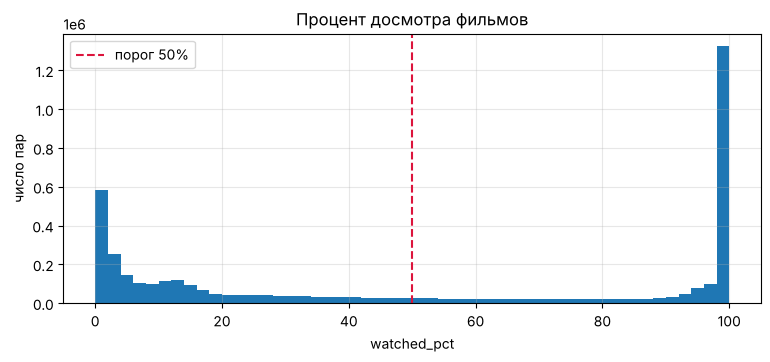

досмотрено меньше 10%: 28.5%
досмотрено меньше 50%: 51.5%
досмотрено меньше 90%: 61.8%


In [9]:
films = typed[typed.content_type == "film"].drop(columns="content_type")
pct = films.watched_pct.dropna()

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(pct, bins=50)
ax.axvline(50, color="crimson", linestyle="--", label="порог 50%")
ax.set(title="Процент досмотра фильмов", xlabel="watched_pct", ylabel="число пар")
ax.legend()
plt.show()

for threshold in [10, 50, 90]:
    print(f"досмотрено меньше {threshold}%: {(pct < threshold).mean():.1%}")

- U-образное распределение с выраженными пиками на границах — около 0% и 100%: большая часть пар  - это либо влключил и сразу выключил (меньше 10%),
либо досмотрел до конца (90% и больше). 

- Середина пустая, следовательно порог можно поставить где угодно в середине,
и разметка почти не поменяется. 

- Я выбрал **50%**: досмотрел хотя бы наполовину == **понравилось**
Порог зафиксирован **до** обучения моделей.

- Просмотр меньше 50% - это **не** «не понравилось». Возможно, человеку просто неудобно было смотреть сейчас.
Из этой мысли потом вырастет собственный таргет пятой модели.

### 2.4. Как просмотры распределены во времени

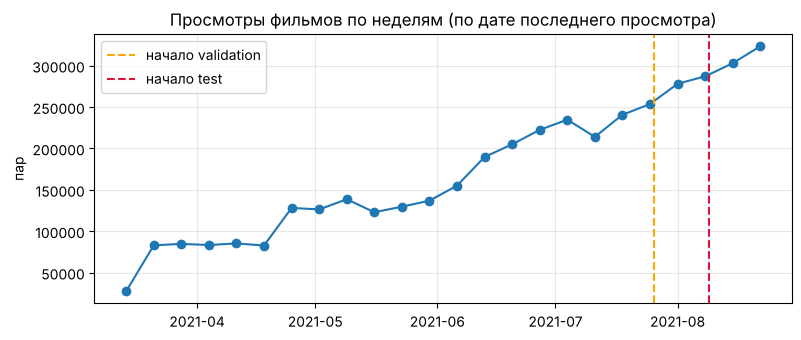

In [10]:
weekly = films.set_index("last_watch_dt").resample("W").size()
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(weekly.index, weekly.values, marker="o")
ax.axvline(pd.Timestamp("2021-07-26"), color="orange", linestyle="--", label="начало validation")
ax.axvline(pd.Timestamp("2021-08-09"), color="crimson", linestyle="--", label="начало test")
ax.set(title="Просмотры фильмов по неделям (по дате последнего просмотра)", ylabel="пар")
ax.legend()
plt.show()

- Сервис рос: к лету просмотров в неделю в несколько раз больше, чем в марте. 

- Последние недели самые загруженные, поэтому я отдаю две последние недели под **test**, две предыдущие — под **validation**, а всё до 26 июля — под **train**.

### 2.5. Активность пользователей и популярность фильмов

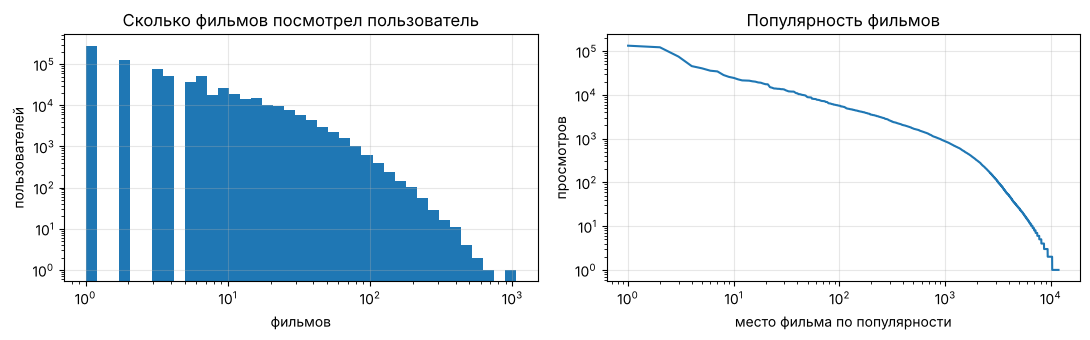

пользователей с одним фильмом: 37.0%, медиана: 2 фильма
1% самых популярных фильмов собирает 37.8% всех просмотров


In [11]:
user_activity = films.groupby("user_id").size()
film_popularity = films.groupby("item_id").size().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(user_activity, bins=np.geomspace(1, user_activity.max() + 1, 40))
axes[0].set(xscale="log", yscale="log", title="Сколько фильмов посмотрел пользователь", xlabel="фильмов", ylabel="пользователей")
axes[1].loglog(np.arange(1, len(film_popularity) + 1), film_popularity.values)
axes[1].set(title="Популярность фильмов", xlabel="место фильма по популярности", ylabel="просмотров")
plt.tight_layout()
plt.show()

top = film_popularity.head(int(0.01 * len(film_popularity))).sum() / len(films)
print(f"пользователей с одним фильмом: {(user_activity == 1).mean():.1%}, медиана: {user_activity.median():.0f} фильма")
print(f"1% самых популярных фильмов собирает {top:.1%} всех просмотров")

Ключевое:

- **Пользователи:** у 1/3 всего один фильм. По одному фильму о вкусе почти ничего не узнать, поэтому дальше я оставлю
  пользователей хотя бы с 5 фильмами.

- **Фильмы:** Большая часть просмотров приходится на небольшое число популярных фильмов. Рекомендации по популярности могут давать неплохой результат, так что их стоит взять как baseline для сравнения с другими моделями.

### 2.6. Метаданные фильмов

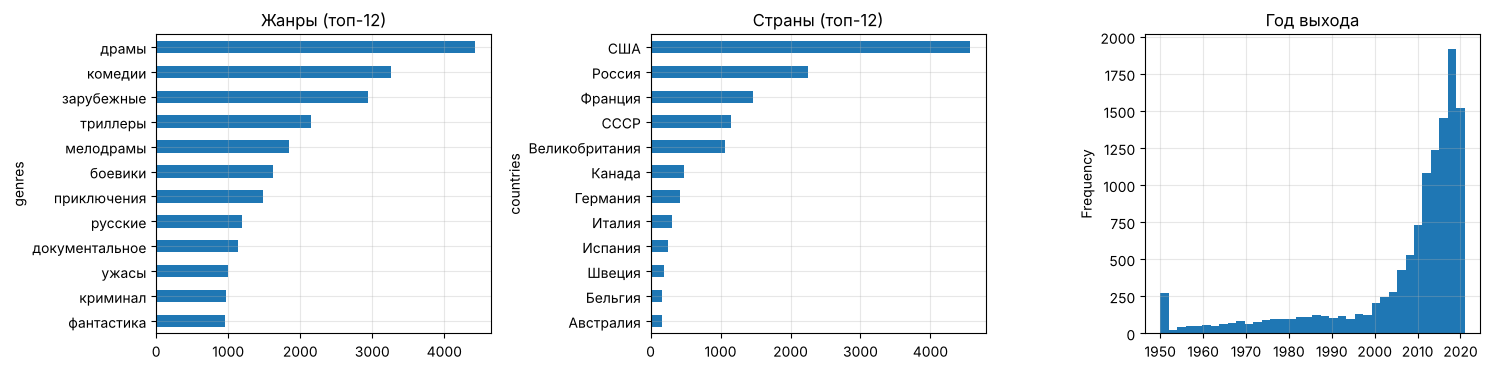

жанров: 79, стран: 90, у фильма в среднем жанров: 2.6


In [12]:
film_items = items[items.content_type == "film"]
genres = film_items.genres.dropna().str.split(", ").explode().value_counts()
countries = film_items.countries.dropna().str.split(", ").explode().value_counts()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
genres.head(12).sort_values().plot.barh(ax=axes[0], title="Жанры (топ-12)")
countries.head(12).sort_values().plot.barh(ax=axes[1], title="Страны (топ-12)")
film_items.release_year.clip(1950, 2021).plot.hist(bins=36, ax=axes[2], title="Год выхода")
plt.tight_layout()
plt.show()
print(f"жанров: {genres.size}, стран: {countries.size}, у фильма в среднем жанров: {film_items.genres.str.count(',').mean() + 1:.1f}")

У каждого фильма есть жанры, страны и год выпуска. Эти признаки можно использовать в FM, чтобы находить сходства даже между фильмами, у которых мало общих зрителей. Актёров и режиссёров я решил не учитывать, так как их слишком много и большинство встречается всего в одном-двух фильмах.

### 2.7. Пользователи

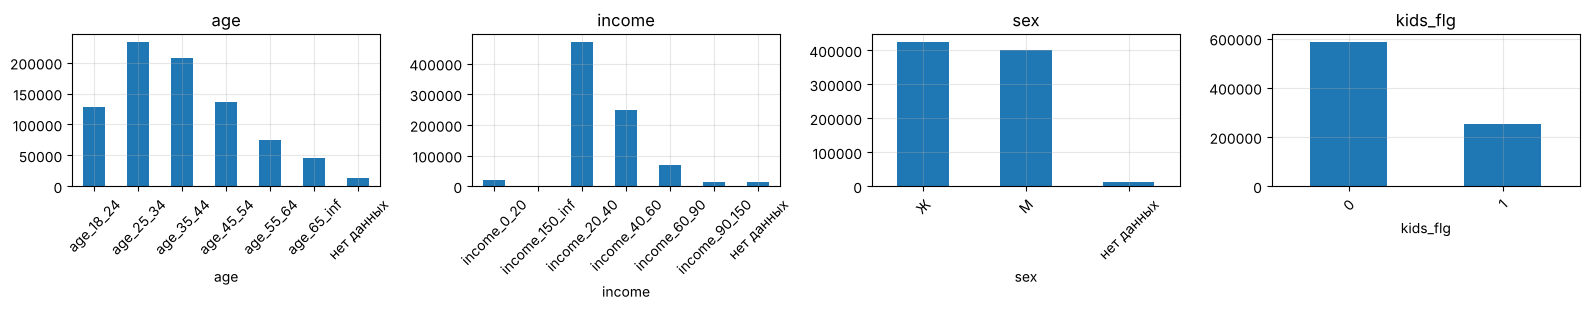

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
for ax, column in zip(axes, ["age", "income", "sex", "kids_flg"]):
    users[column].fillna("нет данных").astype(str).value_counts().sort_index().plot.bar(ax=ax, title=column, rot=45)
plt.tight_layout()
plt.show()

Возраст и доход уже разделены на интервалы, так что их можно сразу использовать в FM как категориальные признаки. Если какие-то данные отсутствуют, для них можно создать отдельную категорию - "нет данных".

## 3. Подготовка выборки

Моя работа с данными и обоснования:

1. **Взял только фильмы** — из-за процента досмотра у сериалов (обоснование в разделе 2.2).
2. **Разделил данные по времени**: train — до 25 июля включительно, validation — 26 июля – 8 августа, test — 9–22 августа.
3. **Отфильтровал данные по train**: оставил фильмы, которые посмотрели хотя бы 5 пользователей, и пользователей, у которых было хотя бы 5 просмотров таких фильмов. Фильтрацию проводил только на train, чтобы не использовать информацию из будущих периодов.
4. **Случайно выбрал 30 000 пользователей**, чтобы уложиться в лимит задания до 2 млн взаимодействий.
   Беру именно пользователей, а не случайные строки, чтобы у каждого осталась вся история.
5. **Сформировал каталог рекомендаций** — фильмы, которые эти пользователи смотрели в train. Модель будет рекомендовать только фильмы из этого каталога.

In [ ]:
VAL_START = pd.Timestamp("2021-07-26")
TEST_START = pd.Timestamp("2021-08-09")

past = films[films.last_watch_dt < VAL_START]
film_counts = past.item_id.value_counts()
good_items = film_counts.index[film_counts >= 5]
past = past[past.item_id.isin(good_items)]
user_counts = past.user_id.value_counts()
good_users = np.sort(user_counts.index[user_counts >= 5].to_numpy())

rng = np.random.default_rng(SEED)
user_ids = np.sort(rng.choice(good_users, size=30_000, replace=False))
sample = films[films.user_id.isin(user_ids) & films.item_id.isin(good_items)]

item_ids = np.sort(sample.loc[sample.last_watch_dt < VAL_START, "item_id"].unique())
outside_catalog = (~sample.item_id.isin(item_ids)).sum()
sample = sample[sample.item_id.isin(item_ids)].copy()

sample["uid"] = np.searchsorted(user_ids, sample.user_id)
sample["iid"] = np.searchsorted(item_ids, sample.item_id)
sample["relevant"] = sample.watched_pct >= 50   
sample = sample.sort_values(["uid", "iid"]).reset_index(drop=True)

N_USERS, N_ITEMS = len(user_ids), len(item_ids)
catalog = items.set_index("item_id").loc[item_ids].reset_index()  

pd.DataFrame({"строк": [
    len(interactions), len(films), len(films[films.user_id.isin(good_users)]), len(sample) + outside_catalog, len(sample),
]}, index=[
    "все взаимодействия", "только фильмы", "все просмотры пользователей с ≥5 фильмами в train",
    "случайные 30 000 из них, фильмы с ≥5 зрителями", "без фильмов вне каталога",
])

,строк
все взаимодействия,5476251
только фильмы,4137134
все просмотры пользователей с ≥5 фильмами в train,2609496
"случайные 30 000 из них, фильмы с ≥5 зрителями",470400
без фильмов вне каталога,470137


In [15]:
assert 100_000 <= len(sample) <= 2_000_000 and N_USERS >= 1000 and N_ITEMS >= 1000  # условия задания
print(f"итог: {len(sample):,} взаимодействий, {N_USERS:,} пользователей, {N_ITEMS:,} фильмов")
print(f"заполненность матрицы: {len(sample) / (N_USERS * N_ITEMS):.2%}")
print(f"просмотров в validation/test по фильмам вне каталога (выкинуты): {outside_catalog}")

итог: 470,137 взаимодействий, 30,000 пользователей, 6,880 фильмов
заполненность матрицы: 0.23%
просмотров в validation/test по фильмам вне каталога (выкинуты): 263


In [ ]:
train = sample[sample.last_watch_dt < VAL_START]
validation = sample[(sample.last_watch_dt >= VAL_START) & (sample.last_watch_dt < TEST_START)]
test = sample[sample.last_watch_dt >= TEST_START]
train_val = pd.concat([train, validation]).sort_values(["uid", "iid"]) 

assert train.last_watch_dt.max() < validation.last_watch_dt.min() <= validation.last_watch_dt.max() < test.last_watch_dt.min()

pd.DataFrame([{
    "часть": name, "с": part.last_watch_dt.min().date(), "по": part.last_watch_dt.max().date(),
    "взаимодействий": len(part), "доля релевантных": round(part.relevant.mean(), 3),
    "пользователей": part.uid.nunique(), "пользователей с релевантными": part[part.relevant].uid.nunique(),
} for name, part in [("train", train), ("validation", validation), ("test", test)]])

,часть,с,по,взаимодействий,доля релевантных,пользователей,пользователей с релевантными
0,train,2021-03-13,2021-07-25,398450,0.548,30000,28551
1,validation,2021-07-26,2021-08-08,40730,0.457,10093,6631
2,test,2021-08-09,2021-08-22,30957,0.440,8522,5243


- Полученная выборка соответствует ограничениям задания. При этом я оставил только пользователей, которые посмотрели хотя бы 5 фильмов. Это важно учитывать при оценке результатов: модель работает с пользователями, у которых уже есть история просмотров. Проблему холодного старта в этой работе я не рассматриваю.

- Каждая пара пользователь–фильм встречается в данных только один раз. Это значит, что фильмы из validation и test пользователь раньше не смотрел, и модель не будет рекомендовать ему уже просмотренное.

## 4. Моя оценка модели

### Постановка задачи

Для каждого пользователя модель рекомендует 10 фильмов, которые он ещё не смотрел. Рекомендация считается успешной, если пользователь посмотрел хотя бы 50% фильма в период validation или test.

### Оценка моделей

Оцениваю только пользователей, у которых за этот период был хотя бы один такой просмотр.

Использую три метрики:

- **Recall@10** — какую долю подходящих фильмов модель смогла порекомендовать.
  $$Recall@10 = \frac{|\text{top-10} \cap R_u|}{|R_u|}$$
- **NDCG@10** — учитывает не только попадание в рекомендации, но и позицию фильма. Чем выше подходящий фильм в списке, тем лучше.
  $$DCG@10 = \sum_{r=1}^{10} \frac{[\text{фильм на месте } r \in R_u]}{\log_2(r+1)}, \qquad NDCG@10 = \frac{DCG@10}{\text{лучший возможный } DCG@10}$$
- **Coverage@10** — показывает, какая доля фильмов из каталога хотя бы раз попала в рекомендации. Помогает понять, не рекомендует ли модель всем одни и те же фильмы.

Метрики сначала считаю для каждого пользователя, затем усредняю.

### Выбор лучшей модели

**Основная метрика — NDCG@10**, так как важно не только рекомендовать подходящие фильмы, но и ставить их выше в списке.

По этой метрике подбираю параметры моделей на **validation**. Затем переобучаю модели на **train + validation** и один раз проверяю результат на **test**.

In [ ]:
def to_matrix(frame, values=None):
    values = np.ones(len(frame), dtype=np.float32) if values is None else np.asarray(values, dtype=np.float32)
    return csr_matrix((values, (frame.uid.to_numpy(), frame.iid.to_numpy())), shape=(N_USERS, N_ITEMS))


def make_split(history, period):
    truth = period[period.relevant].groupby("uid").iid.apply(np.array)
    return {"users": truth.index.to_numpy(), "truth": truth.to_list(), "seen": to_matrix(history)}


def top_k(scores, seen, users, k=K):
    scores = np.array(scores, dtype=np.float64)
    for row, user in enumerate(users):
        scores[row, seen[user].indices] = -np.inf
    top = np.argpartition(-scores, k, axis=1)[:, :k]
    order = np.argsort(-np.take_along_axis(scores, top, axis=1), axis=1, kind="stable")
    return np.take_along_axis(top, order, axis=1)


DISCOUNT = 1 / np.log2(np.arange(2, K + 2))  


def user_metrics(recs, relevant):
    hits = np.isin(recs, relevant)
    ndcg = (hits * DISCOUNT).sum() / DISCOUNT[:min(len(relevant), K)].sum()
    recall = hits.sum() / len(relevant)
    return ndcg, recall


def evaluate(score_fn, split, batch_size=2000):
    rows, shown = [], set()
    for start in range(0, len(split["users"]), batch_size):
        batch = split["users"][start:start + batch_size]
        recs = top_k(score_fn(batch), split["seen"], batch)
        shown.update(recs.ravel().tolist())
        rows += [user_metrics(r, rel) for r, rel in zip(recs, split["truth"][start:start + batch_size])]
    per_user = pd.DataFrame(rows, columns=["NDCG@10", "Recall@10"])
    summary = {"NDCG@10": per_user["NDCG@10"].mean(), "Recall@10": per_user["Recall@10"].mean(),
               "Coverage@10": len(shown) / N_ITEMS}
    return summary, per_user

Проверка метрик на примере:

In [18]:
pd.DataFrame([
    {"где в десятке": "места 1 и 2", **dict(zip(["NDCG@10", "Recall@10"], user_metrics(np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10]), [1, 2])))},
    {"где в десятке": "места 9 и 10", **dict(zip(["NDCG@10", "Recall@10"], user_metrics(np.array([3, 4, 5, 6, 7, 8, 9, 10, 1, 2]), [1, 2])))},
    {"где в десятке": "не попали", **dict(zip(["NDCG@10", "Recall@10"], user_metrics(np.array([3, 4, 5, 6, 7, 8, 9, 10, 11, 12]), [1, 2])))},
])

,где в десятке,NDCG@10,Recall@10
0,места 1 и 2,1.000000,1.0
1,места 9 и 10,0.361815,1.0
2,не попали,0.000000,0.0


В обоих случаях Recall одинаковый, так как модель угадала оба фильма. А вот NDCG заметно ниже, когда подходящие фильмы стоят в конце списка. Значит, метрики работают правильно.

Дальше готовлю данные для подбора параметров на validation: историю просмотров из train и фильмы, которые пользователи досмотрели в validation.

In [ ]:
val_split = make_split(train, validation)
X_train = to_matrix(train)                               
pos_train = to_matrix(train[train.relevant])              
print(f"оцениваю на validation {len(val_split['users']):,} пользователей, "
      f"в среднем {np.mean([len(t) for t in val_split['truth']]):.1f} нужных фильма на человека")

search = [] 


def log(model_name, params, metrics):
    search.append({"модель": model_name, "параметры": params, **metrics})
    return metrics

оцениваю на validation 6,631 пользователей, в среднем 2.8 нужных фильма на человека


## 5. Baseline: популярное

Самый простой вариант - рекомендовать всем самые популярные фильмы, которые чаще всего досматривали в train. Фильмы, которые пользователь уже смотрел, исключаю из рекомендаций.

Этот подход использую как baseline: более сложные модели должны показывать результат лучше него(в теории, посмотрим что будет на практике)

In [20]:
def popularity_scores(positives):
    counts = np.asarray(positives.sum(axis=0)).ravel()
    return lambda users: np.tile(counts, (len(users), 1))

popular_val, _ = evaluate(popularity_scores(pos_train), val_split)
log("Popularity", {}, popular_val)
pd.Series(popular_val).round(4)

NDCG@10        0.1002
Recall@10      0.1317
Coverage@10    0.0044
dtype: float64

Модель популярности рекомендует почти всем одни и те же фильмы, поэтому покрытие каталога меньше 1%. При этом NDCG уже около 0.10 — это результат, с которым буду сравнивать остальные модели.

## 6. Модель 1: ItemKNN 

Для оценки сходства использую косинусную меру со сглаживанием:

$$s_{ij} = \frac{n_{ij}}{\sqrt{n_i \, n_j} + h}$$

Здесь $n_{ij}$ - число пользователей, посмотревших оба фильма, а $n_i$ и $n_j$ - число зрителей каждого фильма.

Параметр $h$ нужен, чтобы фильмы не считались слишком похожими только из-за одного общего зрителя.

Для каждого фильма оставляю $k$ самых похожих. Затем оцениваю новые фильмы по их сходству с историей просмотров пользователя.

**На validation подбираю два параметра:** $k$ — количество похожих фильмов и $h$ — степень сглаживания.

In [21]:
for k, h in product([50, 200, 500, 1000], [10, 50, 200, 500]):
    model = ItemKNN(k=k, shrinkage=h).fit(X_train)
    log("ItemKNN", {"k": k, "shrinkage": h}, evaluate(model.score, val_split)[0])

knn_search = pd.DataFrame([r for r in search if r["модель"] == "ItemKNN"])
knn_search = knn_search.join(pd.json_normalize(knn_search["параметры"].tolist()))
display(knn_search.pivot(index="k", columns="shrinkage", values="NDCG@10").round(4))
best = {"ItemKNN": knn_search.loc[knn_search["NDCG@10"].idxmax(), "параметры"]}
print("лучшие параметры:", best["ItemKNN"])

shrinkage,10,50,200,500
k,,,,
50,0.1183,0.1193,0.1221,0.1223
200,0.1206,0.1222,0.1233,0.1222
500,0.1227,0.1224,0.1235,0.1225
1000,0.1218,0.1225,0.1236,0.1228


лучшие параметры: {'k': 1000, 'shrinkage': 200}


- Сглаживание улучшает результат: при $h = 10$ модель чаще считает похожими редкие фильмы, у которых случайно совпали зрители. При этом увеличение числа соседей после 200 почти не влияет на метрику.

- Теперь проверю, какие фильмы модель считает похожими. Для этого возьму три фильма разной популярности: 1-й, 50-й и 500-й по числу зрителей в train.

In [22]:
knn = ItemKNN(**best["ItemKNN"]).fit(X_train)
viewers = np.asarray(X_train.sum(axis=0)).ravel()
by_popularity = np.argsort(-viewers, kind="stable")

for place in [0, 49, 499]:
    item = by_popularity[place]
    neighbours, similarity = knn.neighbours(item)
    common = (X_train[:, [item]].T @ X_train[:, neighbours]).toarray().ravel()
    display(Markdown(f"**{catalog.title[item]}** ({catalog.genres[item]}) — {place + 1}-й по популярности, {int(viewers[item])} зрителей"))
    display(pd.DataFrame({
        "похожий фильм": catalog.title[neighbours].values, "жанры": catalog.genres[neighbours].values,
        "сходство": similarity.round(3), "общих зрителей": common.astype(int),
    }))

**Девятаев** (драмы, военные, приключения) — 1-й по популярности, 8621 зрителей

,похожий фильм,жанры,сходство,общих зрителей
0,Гнев человеческий,"боевики, триллеры",0.415,3499
1,Восемь сотен,"боевики, драмы, историческое, военные",0.368,1822
2,Прабабушка легкого поведения,комедии,0.347,2441
3,Маша,"драмы, триллеры",0.283,1741
4,Белый снег,"драмы, спорт",0.267,1481


**Терминатор: Тёмные судьбы** (боевики, фантастика, приключения) — 50-й по популярности, 923 зрителей

,похожий фильм,жанры,сходство,общих зрителей
0,Гнев человеческий,"боевики, триллеры",0.108,312
1,Мстители: Война бесконечности,"боевики, фантастика, приключения",0.103,136
2,Мстители: Финал,"боевики, драмы, фантастика",0.097,127
3,Девятаев,"драмы, военные, приключения",0.095,286
4,Алита: Боевой ангел,"боевики, фантастика, триллеры, приключения",0.093,104


**Ничего хорошего в отеле «Эль Рояль»** (драмы, триллеры, криминал) — 500-й по популярности, 178 зрителей

,похожий фильм,жанры,сходство,общих зрителей
0,Гнев человеческий,"боевики, триллеры",0.059,81
1,Аферистка,"триллеры, комедии",0.055,49
2,Денежная игла,триллеры,0.047,37
3,Крёстная мама,"драмы, комедии",0.044,30
4,Маша,"драмы, триллеры",0.043,45


**Вывод**: 

Что видно из соседей:

По соседям видно, что модель часто находит фильмы похожих жанров, даже без информации о них. Например, у «Терминатора» в соседях «Мстители» и «Алита», а у «Эль Рояль» -  другие триллеры.

При этом есть смещение в сторону популярных фильмов. Например, «Гнев человеческий» попал в соседи ко всем трём фильмам, а у «Девятаева» в основном другие хиты разных жанров.

## 7. Модель 2: iALS 

Использую ALS для неявной обратной связи. Модель строит векторы пользователей и фильмов, на основе которых оценивает, насколько фильм подходит пользователю.

Так как у нас есть только история просмотров, задаю:

- $p_{ui} = 1$, если пользователь смотрел фильм, и $0$ — если нет.
- $c_{ui} = 1 + \alpha$ для просмотренных фильмов и $1$ для остальных. Это позволяет учитывать просмотры как более сильный сигнал интереса.

Функция потерь:

$$\min_{X,Y} \sum_{u,i} c_{ui}(p_{ui} - x_u^\top y_i)^2 + \lambda(\|X\|^2 + \|Y\|^2)$$

Модель поочерёдно обновляет векторы пользователей и фильмов, минимизируя ошибку.

На validation подбираю число факторов, $\alpha$, регуляризацию $\lambda$ и число итераций. Результат проверяю после 5, 10 и 15 итераций.

In [23]:
for factors, alpha, reg in product([32, 64], [10, 40], [100, 500, 1000, 3000]):
    def checkpoint(model, iteration, params={"factors": factors, "alpha": alpha, "reg": reg}):
        if iteration in (5, 10, 15):
            log("iALS", {**params, "iterations": iteration}, evaluate(model.score, val_split)[0])
    IALS(factors=factors, alpha=alpha, reg=reg, iterations=15, seed=SEED).fit(X_train, callback=checkpoint)

ials_search = pd.DataFrame([r for r in search if r["модель"] == "iALS"])
ials_search = ials_search.join(pd.json_normalize(ials_search["параметры"].tolist()))
best["iALS"] = ials_search.loc[ials_search["NDCG@10"].idxmax(), "параметры"]
display(ials_search[ials_search.iterations == 15].pivot_table(index=["factors", "alpha"], columns="reg", values="NDCG@10").round(4))
print("лучшие параметры:", best["iALS"])

reg              100     500     1000    3000
factors alpha                                
32      10     0.0850  0.1028  0.0982  0.0997
        40     0.0875  0.1097  0.1111  0.0977
64      10     0.0780  0.1030  0.0982  0.0997
        40     0.0823  0.1110  0.1112  0.0977

лучшие параметры: {'factors': 64, 'alpha': 40, 'reg': 500, 'iterations': 10}


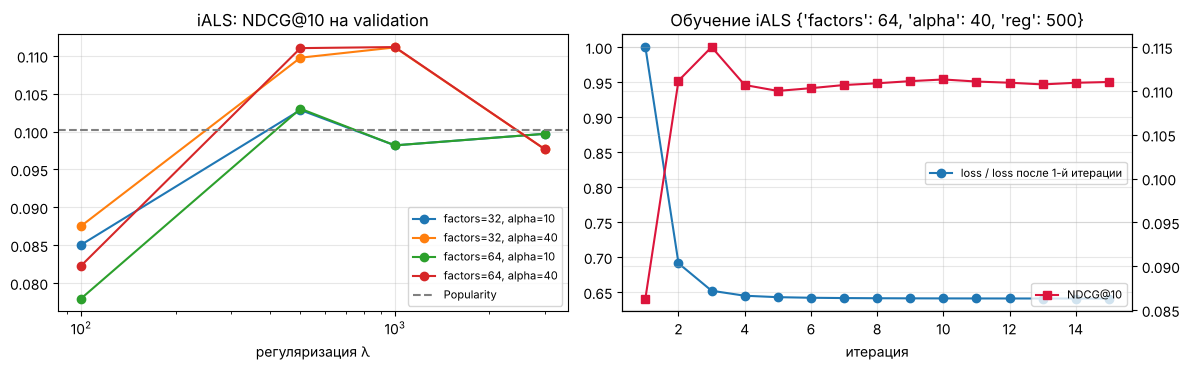

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for (factors, alpha), part in ials_search[ials_search.iterations == 15].groupby(["factors", "alpha"]):
    axes[0].plot(part.reg, part["NDCG@10"], marker="o", label=f"factors={factors}, alpha={alpha}")
axes[0].axhline(popular_val["NDCG@10"], color="gray", linestyle="--", label="Popularity")
axes[0].set(xscale="log", title="iALS: NDCG@10 на validation", xlabel="регуляризация λ")
axes[0].legend(fontsize=8)

# кривая обучения для лучших параметров: функция потерь падает, а метрика быстро выходит на плато
params = {k: v for k, v in best["iALS"].items() if k != "iterations"}
curve = []
model = IALS(**params, iterations=15, seed=SEED).fit(
    X_train, callback=lambda m, it: curve.append((it, m.history[-1], evaluate(m.score, val_split)[0]["NDCG@10"])))
curve = pd.DataFrame(curve, columns=["итерация", "loss", "NDCG@10"])
axes[1].plot(curve["итерация"], curve["loss"] / curve["loss"].iloc[0], marker="o", label="loss / loss после 1-й итерации")
ax2 = axes[1].twinx()
ax2.plot(curve["итерация"], curve["NDCG@10"], marker="s", color="crimson", label="NDCG@10")
axes[1].set(title=f"Обучение iALS {params}", xlabel="итерация")
axes[1].legend(loc="center right", fontsize=8)
ax2.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

**Выводы:**

- **Сильнее всего на качество влияет регуляризация.** При $\lambda = 100$ модель переобучается, а при $\lambda = 3000$ слишком сильно ограничивается. В обоих случаях результат хуже baseline по популярности. Лучше всего работают значения 500–1000.
- **$\alpha = 40$ работает лучше, чем $\alpha = 10$.** Модели полезно придавать просмотрам больший вес.
- **Число факторов (32 или 64)** почти не влияет на результат по сравнению с регуляризацией.
- **NDCG почти перестаёт расти после 3–4 итераций**, хотя функция потерь продолжает снижаться. Значит, 10 итераций достаточно, а уменьшение ошибки обучения не всегда улучшает рекомендации.

## 8. Модель 3: EASE 

Использую EASE -  модель, которая учится предсказывать интерес к фильмам на основе истории просмотров. Для этого строю матрицу весов $B$, где каждый вес показывает, насколько просмотр одного фильма связан с другим.

Модель обучается так, чтобы по истории просмотров восстанавливать эту же историю:

$$\min_B \|X - XB\|^2 + \lambda \|B\|^2, \qquad B_{ii} = 0$$

Диагональ матрицы обнуляю, чтобы фильм не мог предсказывать сам себя.

Веса можно вычислить напрямую:

$$P = (X^\top X + \lambda I)^{-1}, \qquad B_{ij} = -\frac{P_{ij}}{P_{jj}}$$

В отличие от ItemKNN, EASE учитывает связи между всеми фильмами сразу. При этом веса могут быть отрицательными, если просмотр одного фильма снижает вероятность интереса к другому.

**На validation подбираю только один параметр** - регуляризацию $\lambda$.

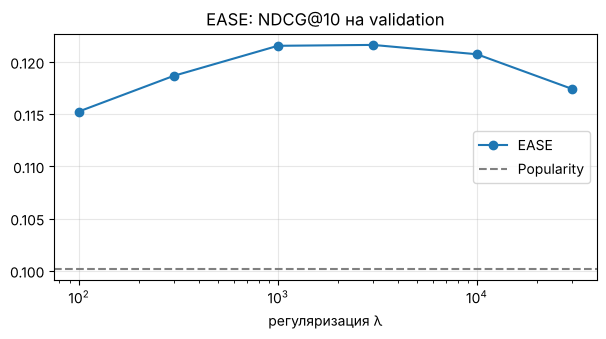

,reg,NDCG@10,Recall@10,Coverage@10
0,100,0.1152,0.1609,0.1619
1,300,0.1187,0.1650,0.1235
2,1000,0.1215,0.1668,0.0903
3,3000,0.1216,0.1659,0.0672
4,10000,0.1207,0.1627,0.0478
5,30000,0.1174,0.1583,0.0358


лучшие параметры: {'reg': 3000}


In [25]:
for reg in [100, 300, 1000, 3000, 10000, 30000]:
    model = EASE(reg=reg).fit(X_train)
    log("EASE", {"reg": reg}, evaluate(model.score, val_split)[0])

ease_search = pd.DataFrame([r for r in search if r["модель"] == "EASE"])
ease_search["reg"] = [p["reg"] for p in ease_search["параметры"]]
best["EASE"] = ease_search.loc[ease_search["NDCG@10"].idxmax(), "параметры"]

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(ease_search.reg, ease_search["NDCG@10"], marker="o", label="EASE")
ax.axhline(popular_val["NDCG@10"], color="gray", linestyle="--", label="Popularity")
ax.set(xscale="log", title="EASE: NDCG@10 на validation", xlabel="регуляризация λ")
ax.legend()
plt.show()
display(ease_search[["reg", "NDCG@10", "Recall@10", "Coverage@10"]].round(4))
print("лучшие параметры:", best["EASE"])

**Вывод**: Лучший результат EASE показывает при среднем значении $\lambda$. При слабой регуляризации модель переобучается, а при слишком сильной начинает рекомендовать в основном популярные фильмы.


## 9. Модель 4: FM

Использую FM, чтобы учитывать не только историю просмотров, но и признаки пользователей и фильмов. Модель оценивает их попарные взаимодействия:

$$s(x) = \sum_j w_j x_j + \sum_{j < k} \langle v_j, v_k \rangle x_j x_k$$

**Признаки:**
- **Пользователь:** ID, возраст, доход, пол, наличие детей.
- **Фильм:** ID, жанры, страны, десятилетие выхода, возрастной рейтинг.

Для жанров и стран использую вес $1/\sqrt{n}$, чтобы фильмы с большим числом признаков не получали преимущество. Пропуски выделяю в категорию `unknown`.

**Обучение:** использую BPR -  для каждого досмотренного фильма выбираю случайный непросмотренный и обучаю модель ставить первый выше второго.

$$\text{loss} = -\log \sigma(s_{u,\text{досмотренный}} - s_{u,\text{случайный}}) + \text{L2}$$

Реализую модель на PyTorch с оптимизатором Adam. Число эпох выбираю по NDCG на validation, проверяя результат каждые две эпохи.

In [28]:
features = build_features(users, items, user_ids, item_ids, use_metadata=True)
(user_idx, _), (item_idx, _), n_features = features
print(f"всего признаков: {n_features:,} (из них ID пользователей и фильмов: {N_USERS + N_ITEMS:,})")
print(f"у пользователя {user_idx.shape[1]} признаков, у фильма до {item_idx.shape[1]}")

всего признаков: 37,074 (из них ID пользователей и фильмов: 36,880)
у пользователя 5 признаков, у фильма до 18


In [29]:
fm_curves = []
for factors, reg in product([32, 64], [1e-4, 1e-3]):
    params = {"factors": factors, "reg": reg, "lr": 0.003}

    def checkpoint(model, epoch, params=params):
        fm_curves.append({**params, "epoch": epoch, "loss": model.history[-1]})
        if epoch % 2 == 0:
            log("FM", {**params, "epochs": epoch}, evaluate(model.score, val_split)[0])

    FactorizationMachine(**params, epochs=16, seed=SEED).fit(X_train, pos_train, features, callback=checkpoint)

fm_search = pd.DataFrame([r for r in search if r["модель"] == "FM"])
fm_search = fm_search.join(pd.json_normalize(fm_search["параметры"].tolist()))
best["FM"] = fm_search.loc[fm_search["NDCG@10"].idxmax(), "параметры"]
display(fm_search.pivot_table(index=["factors", "reg"], columns="epochs", values="NDCG@10").round(4))
print("лучшие параметры:", best["FM"])

epochs              2       4       6       8       10      12      14      16
factors reg                                                                   
32      0.0001  0.0972  0.1011  0.1046  0.1057  0.1080  0.1035  0.1031  0.1025
        0.0010  0.0967  0.1006  0.1041  0.1060  0.1079  0.1041  0.1045  0.1037
64      0.0001  0.0972  0.1063  0.1022  0.1009  0.1052  0.1010  0.1003  0.0993
        0.0010  0.0978  0.1057  0.1023  0.1023  0.1062  0.1029  0.1028  0.1014

лучшие параметры: {'factors': 32, 'reg': 0.0001, 'lr': 0.003, 'epochs': 10}


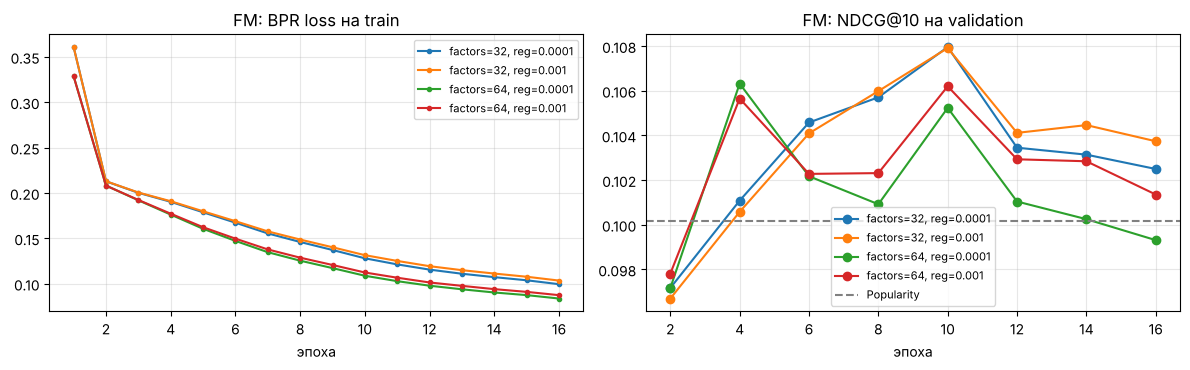

In [30]:
fm_curves = pd.DataFrame(fm_curves)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for (factors, reg), part in fm_curves.groupby(["factors", "reg"]):
    axes[0].plot(part.epoch, part.loss, marker=".", label=f"factors={factors}, reg={reg}")
for (factors, reg), part in fm_search.groupby(["factors", "reg"]):
    axes[1].plot(part.epochs, part["NDCG@10"], marker="o", label=f"factors={factors}, reg={reg}")
axes[1].axhline(popular_val["NDCG@10"], color="gray", linestyle="--", label="Popularity")
axes[0].set(title="FM: BPR loss на train", xlabel="эпоха")
axes[1].set(title="FM: NDCG@10 на validation", xlabel="эпоха")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Модель начинает переобучаться: loss на train продолжает снижаться, но NDCG на validation после 10-й эпохи падает. При этом метрика заметно меняется от эпохи к эпохе. Число эпох выбираю по validation, а регуляризация почти не влияет на результат.

В итоге FM немного лучше baseline по популярности, но заметно уступает ItemKNN и EASE.


**Помогут ли дополнительные признаки?** Для проверки обучаю FM с теми же параметрами, но оставляю только ID пользователей и фильмов.

In [31]:
features_ids = build_features(users, items, user_ids, item_ids, use_metadata=False)
fm_ids = FactorizationMachine(**best["FM"], seed=SEED).fit(X_train, pos_train, features_ids)
fm_ids_val = evaluate(fm_ids.score, val_split)[0]
fm_meta_val = fm_search.loc[fm_search["NDCG@10"].idxmax(), ["NDCG@10", "Recall@10", "Coverage@10"]].to_dict()
pd.DataFrame([fm_meta_val, fm_ids_val], index=["FM: ID + метапризнаки", "FM: только ID"]).round(4)

,NDCG@10,Recall@10,Coverage@10
FM: ID + метапризнаки,0.1080,0.1409,0.0334
FM: только ID,0.1081,0.1444,0.0446


**Дополнительные признаки не улучшили результат.** На validation обе версии FM показывают примерно одинаковый NDCG.

Возможные причины:

- У всех пользователей уже есть история просмотров, поэтому модель может достаточно хорошо определять их интересы по ID. Жанры и страны дают мало дополнительной информации, так как часто повторяются у разных фильмов.
- Возраст, пол и доход тоже не всегда помогают: у многих пользователей эти признаки совпадают, из-за чего модель чаще рекомендует популярные внутри группы фильмы. Это видно и по снижению покрытия каталога.

Дополнительные признаки могут быть полезнее для новых пользователей и фильмов, но холодный старт в этой работе я не рассматриваю.

## 10. Модель 5: iALS с собственным таргетом

В обычном iALS все просмотры считаются одинаковыми: неважно, выключил пользователь фильм через пару минут или досмотрел до конца, но процент досмотра может лучше отражать интерес к фильму.

Я решил учитывать его при расчёте предпочтения:

$$p_{ui} = f + (1-f)\cdot\min\left(\frac{\text{watched\_pct}_{ui}}{50},\ 1\right)$$

Здесь $f$ — минимальное значение предпочтения:

- **0% досмотра** — $p = f$, так как даже короткий просмотр может говорить об интересе.
- **От 0 до 50%** — предпочтение постепенно растёт.
- **От 50%** — $p = 1$, фильм считается интересным.

Параметр $f$ подбираю на validation. При $f = 1$ получаем обычный iALS. Если процент досмотра отсутствует, заменяю его медианой.

**Что меняется:** модель учится оценивать недосмотренные фильмы ниже, чем досмотренные. При этом короткий просмотр не обязательно означает, что фильм не понравился.

Остальные параметры оставляю как у лучшего iALS: меняется только способ расчёта предпочтения.

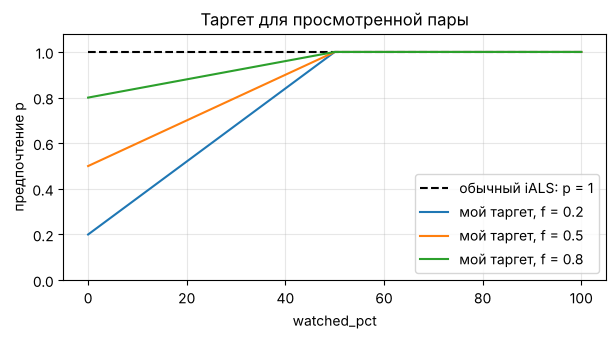

In [32]:
grid = np.linspace(0, 100, 101)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(grid, np.ones_like(grid), "k--", label="обычный iALS: p = 1")
for f in [0.2, 0.5, 0.8]:
    ax.plot(grid, watch_target(grid, floor=f), label=f"мой таргет, f = {f}")
ax.set(xlabel="watched_pct", ylabel="предпочтение p", ylim=(0, 1.08), title="Таргет для просмотренной пары")
ax.legend()
plt.show()

In [33]:
ials_params = best["iALS"]
for floor in [0.0, 0.2, 0.5, 0.8]:
    model = IALSWatchTarget(floor=floor, **ials_params, seed=SEED).fit(X_train, train.watched_pct.to_numpy())
    log("iALS + свой таргет", {**ials_params, "floor": floor}, evaluate(model.score, val_split)[0])

own_search = pd.DataFrame([r for r in search if r["модель"] == "iALS + свой таргет"])
own_search["floor"] = [p["floor"] for p in own_search["параметры"]]
best["iALS + свой таргет"] = own_search.loc[own_search["NDCG@10"].idxmax(), "параметры"]

base = ials_search.loc[ials_search["NDCG@10"].idxmax(), ["NDCG@10", "Recall@10", "Coverage@10"]]
table = own_search.set_index("floor")[["NDCG@10", "Recall@10", "Coverage@10"]]
table.loc["1.0 (= iALS)"] = base
display(table.round(4))
print("лучшие параметры:", best["iALS + свой таргет"])

,NDCG@10,Recall@10,Coverage@10
floor,,,
0.0,0.1123,0.1566,0.0339
0.2,0.1149,0.1596,0.0328
0.5,0.1165,0.1596,0.0378
0.8,0.1139,0.1576,0.0474
1.0 (= iALS),0.1113,0.1566,0.0539


лучшие параметры: {'factors': 64, 'alpha': 40, 'reg': 500, 'iterations': 10, 'floor': 0.5}


**Вывод:** Учёт процента досмотра улучшает результат при всех $f < 1$. Лучше всего работает $f = 0.5$, когда фильм, брошенный в самом начале, получает вдвое меньшую оценку, чем досмотренный.

При слишком маленьком $f$ модель почти не учитывает брошенные фильмы, а при $f$, близком к 1, перестаёт различать короткие и полные просмотры.

**На validation NDCG@10 вырос на 4.7%** по сравнению с обычным iALS: с 0.1113 до 0.1165.

## 11. Итоговое сравнение на test

Для каждой модели беру лучшие параметры с validation и заново обучаю её на train + validation. Затем один раз оцениваю качество на test.

Из рекомендаций исключаю все фильмы, которые пользователь уже смотрел в train и validation.

FM без дополнительных признаков тоже оставляю в таблице для сравнения.

In [34]:
test_split = make_split(train_val, test)
X_full = to_matrix(train_val)
pos_full = to_matrix(train_val[train_val.relevant])
print(f"оцениваю на test {len(test_split['users']):,} пользователей")

final_models = {
    "Popularity": lambda: None,
    "ItemKNN": lambda: ItemKNN(**best["ItemKNN"]).fit(X_full),
    "iALS": lambda: IALS(**best["iALS"], seed=SEED).fit(X_full),
    "EASE": lambda: EASE(**best["EASE"]).fit(X_full),
    "FM (ID + метапризнаки)": lambda: FactorizationMachine(**best["FM"], seed=SEED).fit(X_full, pos_full, features),
    "FM (только ID)": lambda: FactorizationMachine(**best["FM"], seed=SEED).fit(X_full, pos_full, features_ids),
    "iALS + свой таргет": lambda: IALSWatchTarget(**best["iALS + свой таргет"], seed=SEED).fit(
        X_full, train_val.watched_pct.to_numpy()),
}

results, per_user = [], {}
for name, fit in final_models.items():
    started = perf_counter()
    model = fit()
    score_fn = popularity_scores(pos_full) if model is None else model.score
    metrics, per_user[name] = evaluate(score_fn, test_split)
    results.append({"модель": name, **metrics, "время, с": round(perf_counter() - started, 1)})

val_best = pd.DataFrame(search).groupby("модель")["NDCG@10"].max()
results = pd.DataFrame(results).set_index("модель")
results.insert(0, "NDCG@10 (validation)", val_best.rename({"FM": "FM (ID + метапризнаки)"}))
results.loc["FM (только ID)", "NDCG@10 (validation)"] = fm_ids_val["NDCG@10"]
results = results.sort_values("NDCG@10", ascending=False)
results.round(4)

оцениваю на test 5,243 пользователей


,NDCG@10 (validation),NDCG@10,Recall@10,Coverage@10,"время, с"
модель,,,,,
ItemKNN,0.1236,0.1124,0.1494,0.0493,6.0
EASE,0.1216,0.1097,0.1495,0.0574,25.3
iALS + свой таргет,0.1165,0.1038,0.1462,0.0424,33.4
iALS,0.1113,0.1013,0.1420,0.0574,31.4
FM (только ID),0.1081,0.0937,0.1253,0.0411,13.3
FM (ID + метапризнаки),0.1080,0.0904,0.1178,0.0326,70.7
Popularity,0.1002,0.0849,0.1076,0.0044,0.9


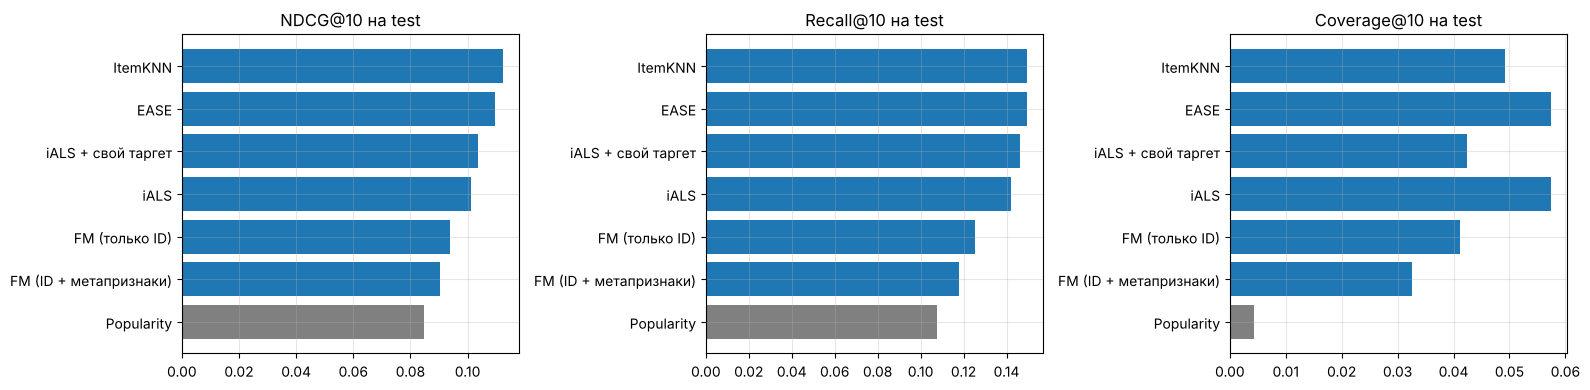

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
ordered = results.sort_values("NDCG@10")
colors = ["gray" if name == "Popularity" else "tab:blue" for name in ordered.index]
for ax, metric in zip(axes, ["NDCG@10", "Recall@10", "Coverage@10"]):
    ax.barh(ordered.index, ordered[metric], color=colors)
    ax.set(title=f"{metric} на test")
plt.tight_layout()
plt.show()

**Проверяю, насколько надёжна разница между моделями.** Для этого использую парный бутстрэп: 1000 раз случайно выбираю пользователей с повторениями и считаю разницу NDCG@10 между моделями.

По полученным результатам строю 95%-й доверительный интервал. Если он не включает ноль, считаю различие статистически значимым.

In [36]:
def paired_bootstrap(a, b, n=1000, seed=SEED):
    diff = per_user[a]["NDCG@10"].to_numpy() - per_user[b]["NDCG@10"].to_numpy()
    rng = np.random.default_rng(seed)
    means = np.array([diff[rng.integers(0, len(diff), len(diff))].mean() for _ in range(n)])
    low, high = np.quantile(means, [0.025, 0.975])
    return {"сравнение": f"{a} − {b}", "разница NDCG@10": diff.mean(), "95% интервал": f"[{low:+.4f}, {high:+.4f}]",
            "устойчиво": "да" if low > 0 or high < 0 else "нет"}

pd.DataFrame([
    paired_bootstrap(results.index[0], "Popularity"),
    paired_bootstrap("ItemKNN", "EASE"),
    paired_bootstrap("iALS + свой таргет", "iALS"),
    paired_bootstrap("FM (ID + метапризнаки)", "FM (только ID)"),
]).round(4)

,сравнение,разница NDCG@10,95% интервал,устойчиво
0,ItemKNN − Popularity,0.0275,"[+0.0235, +0.0315]",да
1,ItemKNN − EASE,0.0027,"[+0.0009, +0.0045]",да
2,iALS + свой таргет − iALS,0.0025,"[+0.0001, +0.0047]",да
3,FM (ID + метапризнаки) − FM (только ID),-0.0034,"[-0.0067, -0.0002]",да


## 12. Выводы

**Итог на test** (параметры выбраны на validation, модели обучены на train + validation):

| Модель | NDCG@10 | Recall@10 | Coverage@10 |
|---|---|---|---|
| ItemKNN | **0.1124** | 0.1494 | 4.9% |
| EASE | 0.1097 | **0.1495** | 5.7% |
| iALS + свой таргет | 0.1038 | 0.1462 | 4.2% |
| iALS | 0.1013 | 0.1420 | 5.7% |
| FM (только ID) | 0.0937 | 0.1253 | 4.1% |
| FM (ID + метапризнаки) | 0.0904 | 0.1178 | 3.3% |
| Popularity | 0.0849 | 0.1076 | 0.4% |


### Итоговые выводы

1. **Лучший результат показал ItemKNN** - NDCG@10 = 0.1124, на 32% выше baseline по популярности. EASE немного уступает по NDCG, но Recall у них практически одинаковый. Бутстрэп подтвердил разницу, хотя она небольшая, поэтому по качеству модели очень близки.

2. **ItemKNN и EASE оказались лучше факторизационных моделей.** Вероятно, это связано с тем, что пользователи часто смотрят одни и те же популярные фильмы и новинки.

3. **iALS тоже обошёл baseline**, но оказался чувствителен к регуляризации. При слишком маленьком или большом $\lambda$ качество заметно падает, поэтому подбор этого параметра особенно важен.

4. **Учёт процента досмотра улучшил iALS.** NDCG вырос с 0.1013 до 0.1038 (+2.5%). Бутстрэп также подтвердил небольшой положительный эффект. Получается, что полезно различать фильмы, которые пользователь бросил в начале, и те, которые досмотрел.

5. **FM показала результаты слабее остальных персональных моделей.** Дополнительные признаки пользователей и фильмов не помогли, а версия только с ID оказалась даже немного лучше. Возможно, для пользователей с историей просмотров этих данных уже достаточно.

6. **На test результаты всех моделей стали ниже**, но их порядок сохранился. Это говорит о том, что выбор моделей на validation в целом оказался удачным. На снижение качества потенциально могли повлиять различия между периодами.

7. **Покрытие каталога остаётся небольшим.** Даже лучшие модели рекомендуют только 5–6% фильмов. Модели всё ещё сильно ориентируются на популярный контент, что не есть хорошо. Для улучшения результата можно было бы использовать reranking.